# Week 1 employee analysis
How many people work in each department, and how does pay compare after cleaning? The original employee file holds the eight salaries supplied by HR. A separate practice file introduces two missing salaries and a duplicate.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
root = next(p for p in (start, *start.parents) if (p / "data" / "employees.csv").is_file())
data = root / "data"
employees = pd.read_csv(data / "employees.csv")
display(employees)

,id,name,department,salary,city
0,1,Arun,Sales,30000,Chennai
1,2,Priya,HR,45000,Chennai
2,3,Rahul,IT,60000,Bangalore
3,4,Divya,IT,75000,Chennai
4,5,Karthik,Finance,90000,Mumbai
5,6,Meena,Sales,52000,Bangalore
6,7,Suresh,IT,68000,Chennai
7,8,Anitha,HR,48000,Mumbai


## Original salaries and Chennai employees

In [2]:
print("Above 50,000:", ", ".join(employees.loc[employees.salary > 50000, "name"]))
display(employees.loc[employees.city == "Chennai", ["id", "name", "salary"]])

Above 50,000: Rahul, Divya, Karthik, Meena, Suresh


,id,name,salary
0,1,Arun,30000
1,2,Priya,45000
3,4,Divya,75000
6,7,Suresh,68000


## Clean the practice data
Remove the duplicate before calculating the median so each employee contributes at most one salary.

In [3]:
raw = pd.read_csv(data / "employees_raw.csv")
print("Duplicate rows:", raw.duplicated().sum())
clean = raw.drop_duplicates().copy()
salary = pd.to_numeric(clean["salary"])
median = salary.median()
clean["imputed"] = salary.isna()
clean["salary"] = salary.fillna(median)
print("Median of known salaries:", median)
display(clean.loc[clean.imputed, ["name", "salary"]])

Duplicate rows: 1
Median of known salaries: 64000.0


,name,salary
1,Priya,64000.0
5,Meena,64000.0


## Department pay and headcount
Start the left join from the department directory to include departments with zero employees.

,department,head,budget,headcount,average_salary,maximum_salary
0,Sales,Latha,1800000,2,47000.00,64000.0
1,HR,Ravi,1600000,2,56000.00,64000.0
2,IT,Asha,3200000,3,67666.67,75000.0
3,Finance,Vijay,1500000,1,90000.00,90000.0
4,Legal,Uma,900000,0,NaN,NaN


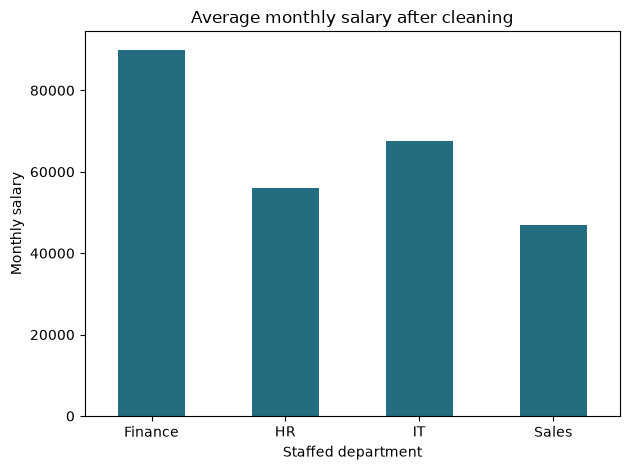

In [4]:
departments = pd.read_csv(data / "departments.csv")
summary = clean.groupby("department", as_index=False).agg(
    headcount=("id", "size"), average_salary=("salary", "mean"), maximum_salary=("salary", "max")
)
report = departments.merge(summary, how="left", on="department", validate="one_to_one")
report["headcount"] = report.headcount.fillna(0).astype(int)
display(report.round(2))
ax = summary.plot.bar(x="department", y="average_salary", legend=False, rot=0, color="#246c80")
ax.set(xlabel="Staffed department", ylabel="Monthly salary", title="Average monthly salary after cleaning")
plt.tight_layout()
plt.show()

## Benchmark the department mean
Time the same aggregation over the eight cleaned rows. The timing depends on the machine.

In [5]:
if get_ipython() is not None:
    %timeit -n 100 -r 3 clean.groupby("department")["salary"].mean()

230 μs ± 36.1 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)

## Payroll concentration

In [6]:
top_three = clean.salary.nlargest(3).sum()
print(f"Top three salaries: {top_three:,.0f} of {clean.salary.sum():,.0f} ({top_three / clean.salary.sum():.1%})")

Top three salaries: 233,000 of 499,000 (46.7%)


## NumPy marks exercise
Columns are Maths, Science and English. Apply 40%, 35% and 25% weights to the original scores.

In [7]:
marks = np.array([[80, 70, 90], [75, 85, 65], [90, 95, 85], [60, 75, 81]])
print("Shape:", marks.shape)
print("Student means:", marks.mean(axis=1))
print("Subject means:", marks.mean(axis=0))
print("Grace marks:", marks + 5, sep="\n")
print("Weighted scores:", np.dot(marks, [0.4, 0.35, 0.25]))

Shape: (4, 3)
Student means: [80. 75. 90. 72.]
Subject means: [76.25 81.25 80.25]
Grace marks:
[[ 85  75  95]
 [ 80  90  70]
 [ 95 100  90]
 [ 65  80  86]]
Weighted scores: [79.  76.  90.5 70.5]
